# Step 5: Model Building

In this notebook, we train multiple machine learning models, compare their performance, and automatically select the best model for predicting house prices.

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

In [2]:
df = pd.read_csv("../data/House Price India.csv")

In [3]:
# Handle missing values

for col in df.columns:

    if df[col].isnull().sum() > 0:

        if df[col].dtype == "object":
            df[col].fillna(df[col].mode()[0], inplace=True)

        else:
            if abs(df[col].skew()) >= 1:
                df[col].fillna(df[col].median(), inplace=True)
            else:
                df[col].fillna(df[col].mean(), inplace=True)

In [4]:
df.head()

,id,Date,number of bedrooms,number of bathrooms,living area,lot area,number of floors,waterfront present,number of views,condition of the house,...,Built Year,Renovation Year,Postal Code,Lattitude,Longitude,living_area_renov,lot_area_renov,Number of schools nearby,Distance from the airport,Price
0,6762810635,42491,4,2.50,2920,4000,1.5,0,0,5,...,1909,0,122004,52.8878,-114.470,2470,4000,2,51,1400000
1,6762810998,42491,5,2.75,2910,9480,1.5,0,0,3,...,1939,0,122004,52.8852,-114.468,2940,6600,1,53,1200000
2,6762812605,42491,4,2.50,3310,42998,2.0,0,0,3,...,2001,0,122005,52.9532,-114.321,3350,42847,3,76,838000
3,6762812919,42491,3,2.00,2710,4500,1.5,0,0,4,...,1929,0,122006,52.9047,-114.485,2060,4500,1,51,805000
4,6762813105,42491,3,2.50,2600,4750,1.0,0,0,4,...,1951,0,122007,52.9133,-114.590,2380,4750,1,67,790000


In [5]:
df["Date"] = pd.to_datetime(df["Date"], unit="D", origin="1899-12-30")

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day

df.drop("Date", axis=1, inplace=True)

In [6]:
X = df.drop("Price", axis=1)
y = df["Price"]

In [7]:
feature_names = X.columns.tolist()

print("Number of features:", len(feature_names))
print("Features:", feature_names)

Number of features: 24
Features: ['id', 'number of bedrooms', 'number of bathrooms', 'living area', 'lot area', 'number of floors', 'waterfront present', 'number of views', 'condition of the house', 'grade of the house', 'Area of the house(excluding basement)', 'Area of the basement', 'Built Year', 'Renovation Year', 'Postal Code', 'Lattitude', 'Longitude', 'living_area_renov', 'lot_area_renov', 'Number of schools nearby', 'Distance from the airport', 'Year', 'Month', 'Day']


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [9]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42)
}

In [10]:
results = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results[name] = {
        "Model": model,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }

In [11]:
results_df = pd.DataFrame({
    name: {
        "MAE": values["MAE"],
        "RMSE": values["RMSE"],
        "R2 Score": values["R2 Score"]
    }
    for name, values in results.items()
}).T

results_df

,MAE,RMSE,R2 Score
Linear Regression,103262.642322,196394.646351,0.739379
Decision Tree,19037.692544,89192.344198,0.946247
Random Forest,15863.879395,70854.032453,0.966078


In [12]:
best_model_name = results_df["R2 Score"].idxmax()

best_model = results[best_model_name]["Model"]

print("Best Model:", best_model_name)

Best Model: Random Forest


In [13]:
import os

model_data = {
    "model": best_model,
    "features": feature_names
}

joblib.dump(model_data, "../models/best_model.pkl")

['../models/best_model.pkl']

In [14]:
if best_model_name == "Random Forest":

    importance = pd.DataFrame({
        "Feature": X.columns,
        "Importance": best_model.feature_importances_
    })

    importance = importance.sort_values("Importance", ascending=False)

    importance.head(10)

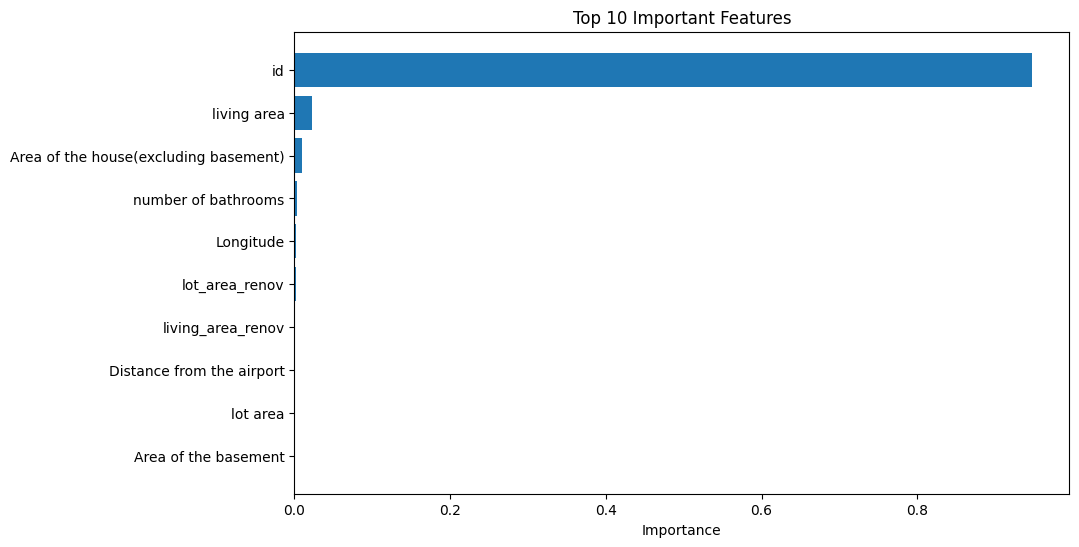

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.barh(
    importance.head(10)["Feature"],
    importance.head(10)["Importance"]
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.gca().invert_yaxis()

plt.show()